In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
data = "global_ai_jobs.csv"
df = pd.read_csv(data)
print(df.shape)
df.head(5)

(90000, 35)


,id,country,job_role,ai_specialization,experience_level,experience_years,salary_usd,bonus_usd,education_required,industry,...,vacation_days,skill_demand_score,automation_risk,job_security_score,career_growth_score,work_life_balance_score,promotion_speed,salary_percentile,cost_of_living_index,employee_satisfaction
0,1,UAE,Machine Learning Engineer,Reinforcement Learning,Entry,0,66465,5395,Master,Automotive,...,27,12,76,57,65,73,15,55,1.23,76
1,2,USA,AI Engineer,LLM,Entry,1,75507,11713,Bootcamp,Retail,...,27,54,29,69,60,51,15,58,0.87,67
2,3,Brazil,Research Scientist,Analytics,Entry,0,41660,5268,PhD,Healthcare,...,13,12,49,70,59,68,37,13,2.13,61
3,4,India,Software Engineer AI,Computer Vision,Senior,6,43268,7975,Diploma,Tech,...,30,80,47,79,65,55,46,74,1.49,56
4,5,Germany,Machine Learning Engineer,Computer Vision,Entry,0,69119,4758,Master,Retail,...,24,82,47,64,52,69,17,21,0.87,72


### Example table to get a clear overview of the variables in the data:

| variable | meaning | unit | type | values/range | missing coding | role | status | notes/concerns |
| -------- | ------- | ---- | ---- | ------------ | -------------- | ---- | ------ | -------------- |
| id | Unique row identifier | None | Integer | Unique per row | NaN | identifier | OK | Drop before modeling |
| country | Country of the job/company | None | String | Country names/codes | NaN | candidate predictor | OK |  |
| job_role | Specific job title | None | String | 'Data Scientist', etc. | NaN | candidate predictor | OK |  |
| ai_specialization | Specific sub-field of AI | None | String | 'NLP', 'Vision', etc. | NaN | candidate predictor | OK |  |
| experience_level | Categorical seniority level | None | String | Entry, Mid, Senior, etc. | NaN | candidate predictor | OK | |
| experience_years | Numeric years of experience | Years | Float/Int | 0 - 40+ | NaN | candidate predictor | OK | Check for correlation with experience_level |
| salary_usd | Standardized base salary | USD | Float/Int | > 0 | NaN | target | OK | Target variable. Check for extreme outliers |
| bonus_usd | Additional cash bonus | USD | Float/Int | >= 0 | NaN / 0 | candidate predictor | Review | High likelihood of zeroes. Add to base for total comp |
| education_required | Minimum degree needed | None | String | Bachelor, Master, PhD | NaN | candidate predictor | OK |  |
| industry | Business sector | None | String | Tech, Finance, Health | NaN | candidate predictor | Review | |
| company_size | Size of the employer | None | String | 'Small', 'Medium', 'Enterprise', 'Large'| NaN | candidate predictor | OK | |
| interview_rounds | Number of hiring interviews | Count | Integer | 1 - 10+ | NaN | candidate predictor | OK |  |
| year | Year data was recorded | Year | Integer | 2020 - 2026 | NaN | date/time | OK |  |
| work_mode | Remote, Hybrid, Onsite | None | String | Remote, Hybrid, Onsite | NaN | candidate predictor | OK |  |
| weekly_hours | Average hours worked per week | Hours | Float/Int | ~20 - 100+ | NaN | candidate predictor | OK |  |
| company_rating | Employee rating of company | Score | Float | 1.0 - 5.0 | NaN | candidate predictor | OK|  |
| job_openings | Current open roles at company | Count | Integer | >= 0 | NaN | candidate predictor | OK |  |
| hiring_difficulty_score | Market difficulty to fill role | Score | Float | Standardized range | NaN | candidate predictor | OK | |
| layoff_risk | Assessed risk of role cut | Score | Float | Standardized range | NaN | candidate predictor | OK |  |
| ai_adoption_score | How heavily company uses AI | Score | Float | Standardized range | NaN | candidate predictor | OK |  |
| company_funding_billion | Total funding or valuation | Bill | Float | >= 0 | NaN / 0 | candidate predictor | Review | Likely heavily right-skewed, many missing for small orgs |
| economic_index | Macroeconomic health metric | Index | Float | Standardized range | NaN | candidate predictor | OK | Highly correlated with year and country |
| ai_maturity_years | Years invested in AI | Years | Int | >= 0 | NaN / 0 | candidate predictor | OK |  |
| offer_acceptance_rate | % offers accepted | % | Float | 0.0 - 1.0 (or 100) | NaN | candidate predictor | OK |  |
| tax_rate_percent | Assumed income tax bracket | % | Float | 0 - 60+ | NaN | candidate predictor | OK |  |
| vacation_days | Number of paid time off days | Days | Integer | >= 0 | NaN | candidate predictor | OK | Varies wildly by country |
| skill_demand_score | Market demand for role skills | Score | Float | Standardized range | NaN | candidate predictor | OK |  |
| automation_risk | Risk of AI automating role | Score | Float | Standardized range | NaN | candidate predictor | OK |  |
| job_security_score | Perceived job stability | Score | Float | Standardized range | NaN | candidate predictor | OK |  |
| career_growth_score | Potential for upward mobility | Score | Float | Standardized range | NaN | candidate predictor | OK |  |
| work_life_balance_score | Subjective WLB rating | Score | Float | Standardized range | NaN | candidate predictor | OK |  |
| promotion_speed | Velocity of career advancement | Score | Num | Months | NaN | candidate predictor | OK |  |
| salary_percentile | Distribution rank of salary | Rank | Float | 0.0 - 1.0 (or 100) | NaN | not relevant | OK | |
| cost_of_living_index | Local cost multiplier | Index | Float | > 0 | NaN | candidate predictor | OK | Correlated with country |
| employee_satisfaction | Overall job satisfaction | Score | Float | Standardized range | NaN | candidate predictor | OK |  |

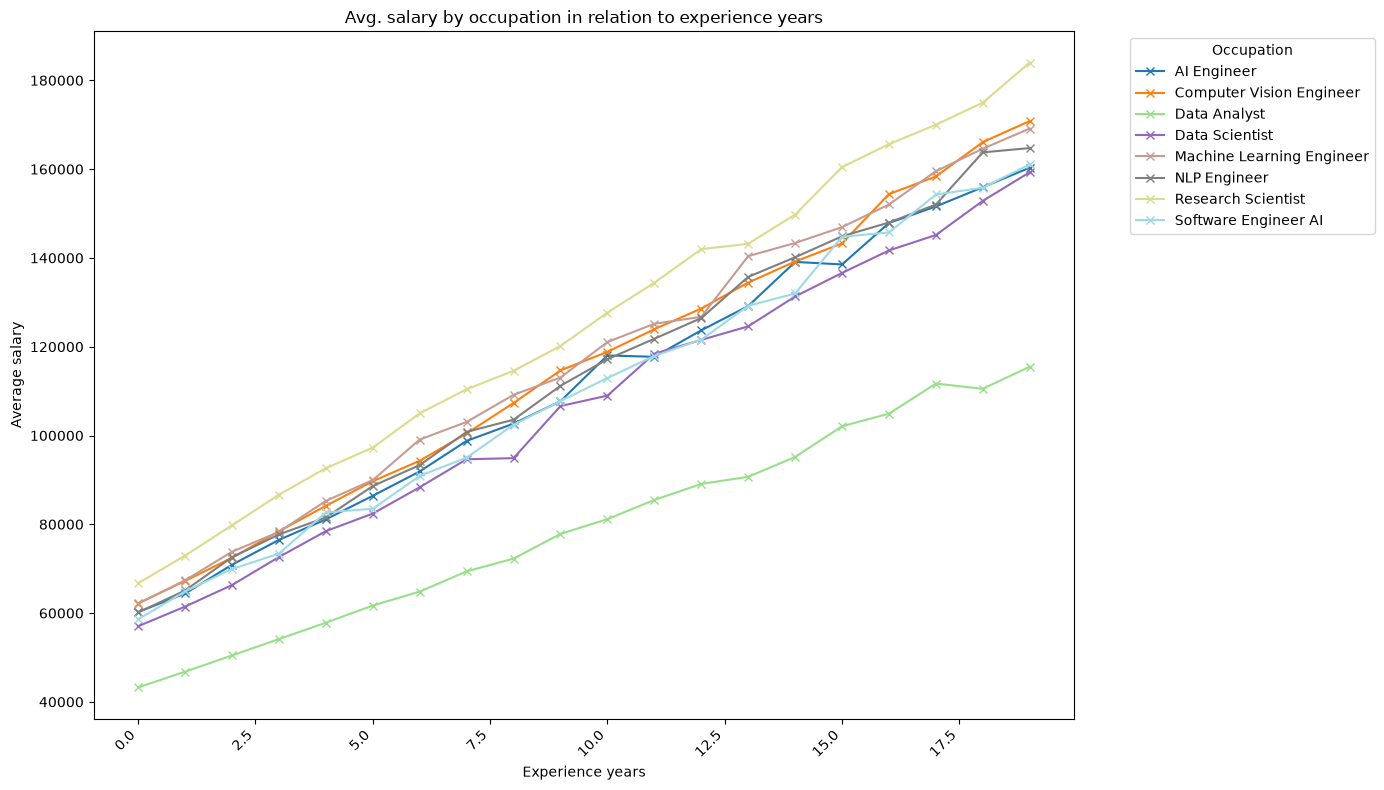

In [3]:
crosstab_df = pd.crosstab(
    index=df['job_role'], 
    columns=df["experience_years"], 
    values=df['salary_usd'], 
    aggfunc='mean'
)

crosstab_df

fig, ax = plt.subplots(figsize=(14, 8))
crosstab_df.T.plot(kind='line', marker='x', ax=ax,colormap='tab20')
plt.title('Avg. salary by occupation in relation to experience years')
plt.xlabel('Experience years')
plt.ylabel('Average salary')
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Occupation')
plt.tight_layout()
plt.show()

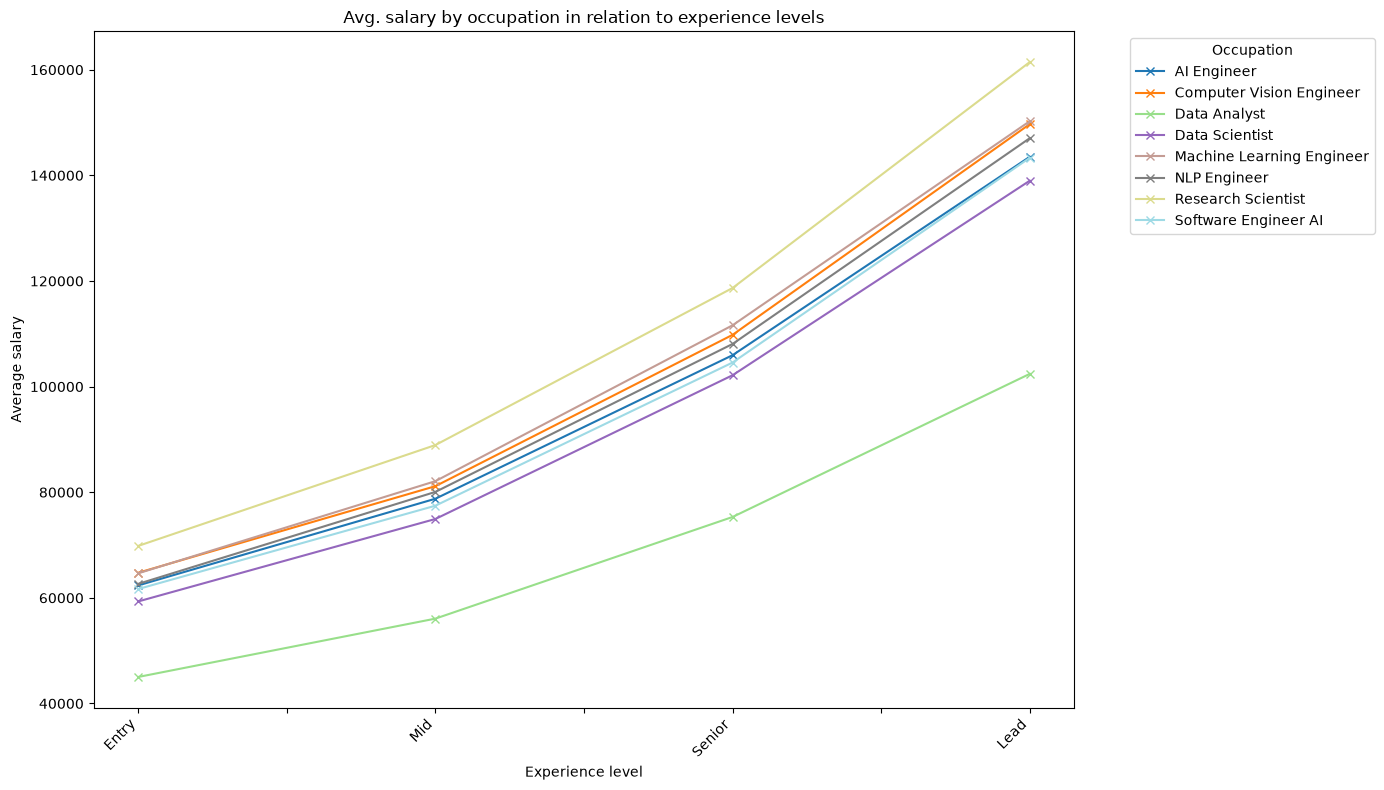

In [4]:
explvl = pd.Categorical(df["experience_level"], categories=["Entry","Mid","Senior","Lead"], ordered=True)
crosstab_df = pd.crosstab(
    index=df['job_role'], 
    columns=explvl, 
    values=df['salary_usd'], 
    aggfunc='mean'
)

crosstab_df

fig, ax = plt.subplots(figsize=(14, 8))
crosstab_df.T.plot(kind='line', marker='x', ax=ax,colormap='tab20')
plt.title('Avg. salary by occupation in relation to experience levels')
plt.xlabel('Experience level')
plt.ylabel('Average salary')
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Occupation')
plt.tight_layout()
plt.show()

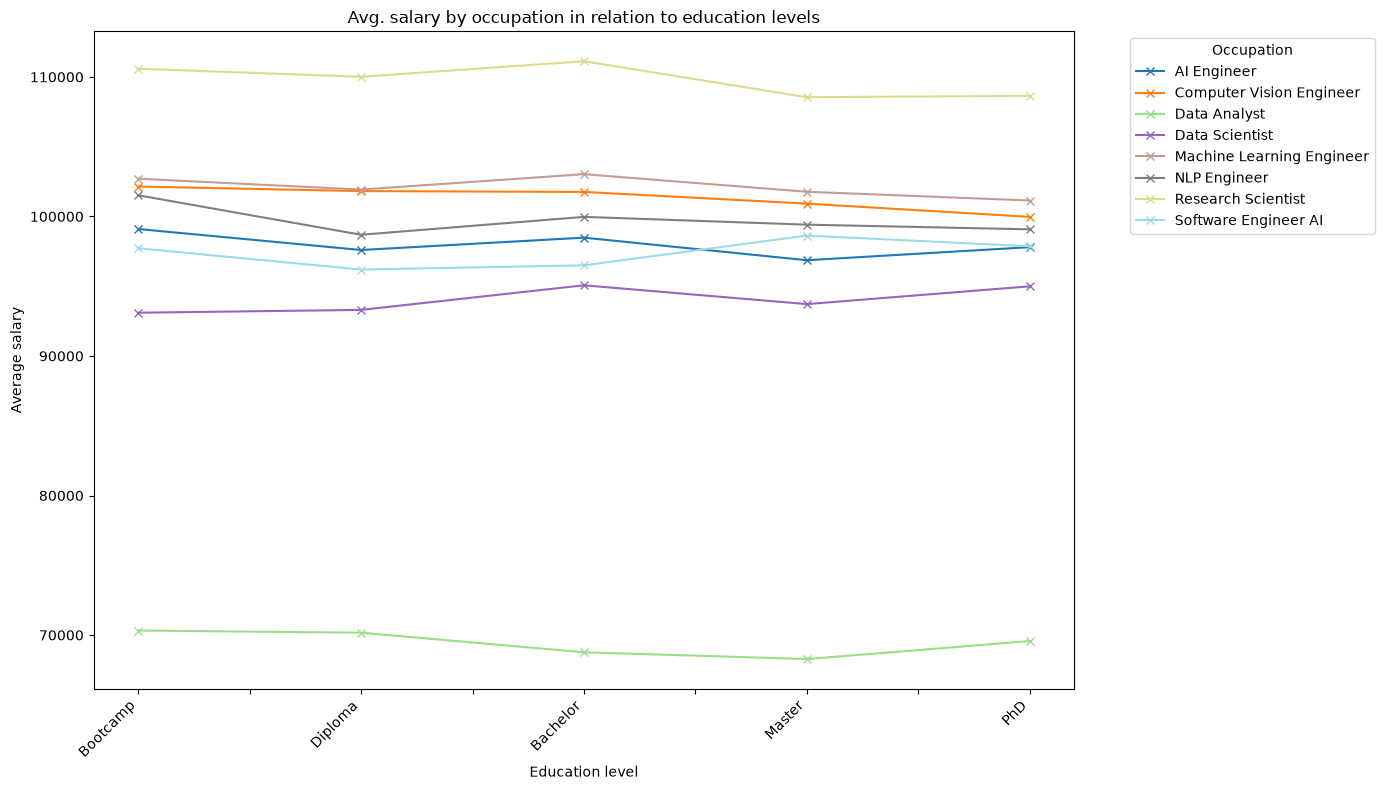

In [5]:
education = pd.Categorical(df["education_required"], categories=["Bootcamp","Diploma","Bachelor","Master","PhD"], ordered=True)
crosstab_df = pd.crosstab(
    index=df['job_role'], 
    columns=education, 
    values=df['salary_usd'], 
    aggfunc='mean'
)

crosstab_df

fig, ax = plt.subplots(figsize=(14, 8))
crosstab_df.T.plot(kind='line', marker='x', ax=ax,colormap='tab20')
plt.title('Avg. salary by occupation in relation to education levels')
plt.xlabel('Education level')
plt.ylabel('Average salary')
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Occupation')
plt.tight_layout()
plt.show()

**Important finding:** Education level generally does not affect people's wages.



In [6]:
for i in range(df.shape[1]):
    print(df.iloc[:,i].value_counts())
    print("---------------------------")

id
1        1
2        1
3        1
4        1
5        1
        ..
89996    1
89997    1
89998    1
89999    1
90000    1
Name: count, Length: 90000, dtype: int64
---------------------------
country
Canada         7602
Australia      7589
Singapore      7583
Brazil         7545
UK             7532
UAE            7529
Netherlands    7514
Germany        7461
India          7450
France         7440
USA            7405
Japan          7350
Name: count, dtype: int64
---------------------------
job_role
NLP Engineer                 11412
Software Engineer AI         11333
Research Scientist           11309
Machine Learning Engineer    11263
AI Engineer                  11247
Computer Vision Engineer     11227
Data Scientist               11146
Data Analyst                 11063
Name: count, dtype: int64
---------------------------
ai_specialization
Computer Vision           11487
LLM                       11466
Reinforcement Learning    11261
Analytics                 11258
Generative AI   

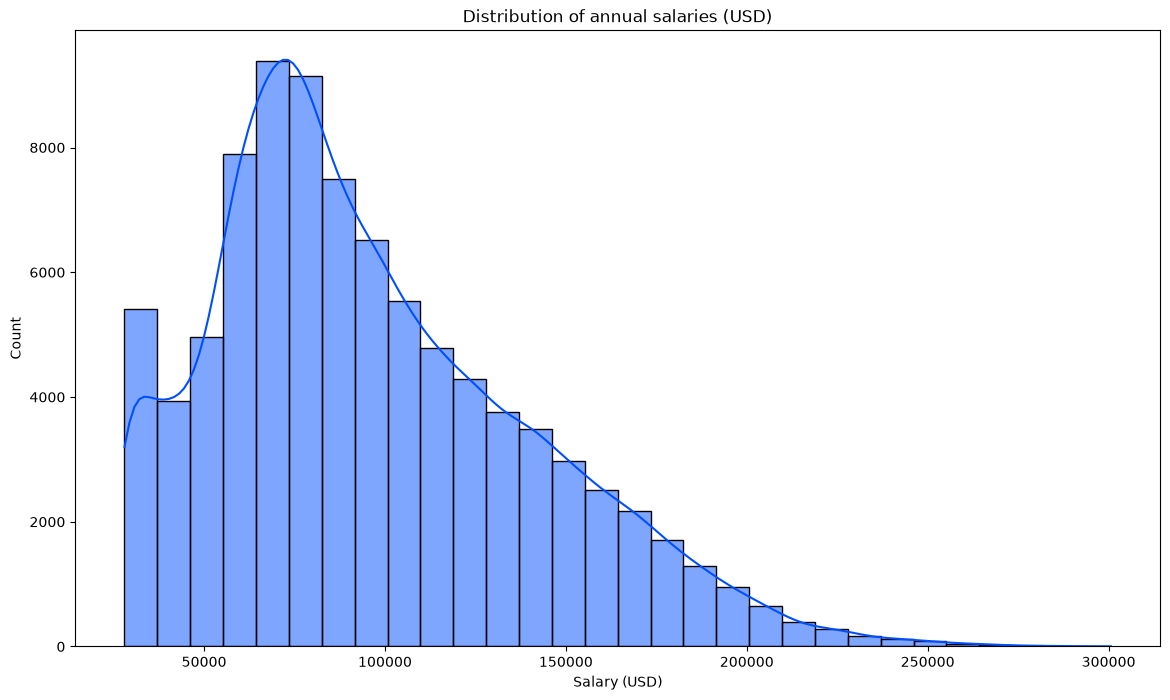

People with a salary of 28000 USD: 1719
Minimum salary: 28000
Maximum salary: 300622
Average salary: 96546.0


In [24]:
fig, ax = plt.subplots(figsize=(14, 8))
sns.histplot(df['salary_usd'], bins=30, kde=True, color='#004FFF')
ax.set_title("Distribution of annual salaries (USD)")
plt.xlabel('Salary (USD)')
plt.show()

print("People with a salary of 28000 USD:", (df['salary_usd'] == 28000).sum())
print("Minimum salary:", df['salary_usd'].min())
print("Maximum salary:", df['salary_usd'].max())
print("Average salary:", np.round(df['salary_usd'].mean()))

**Important finding:** The seems to be a floor boundary where salaries below 28000 are rounded up to 28000.

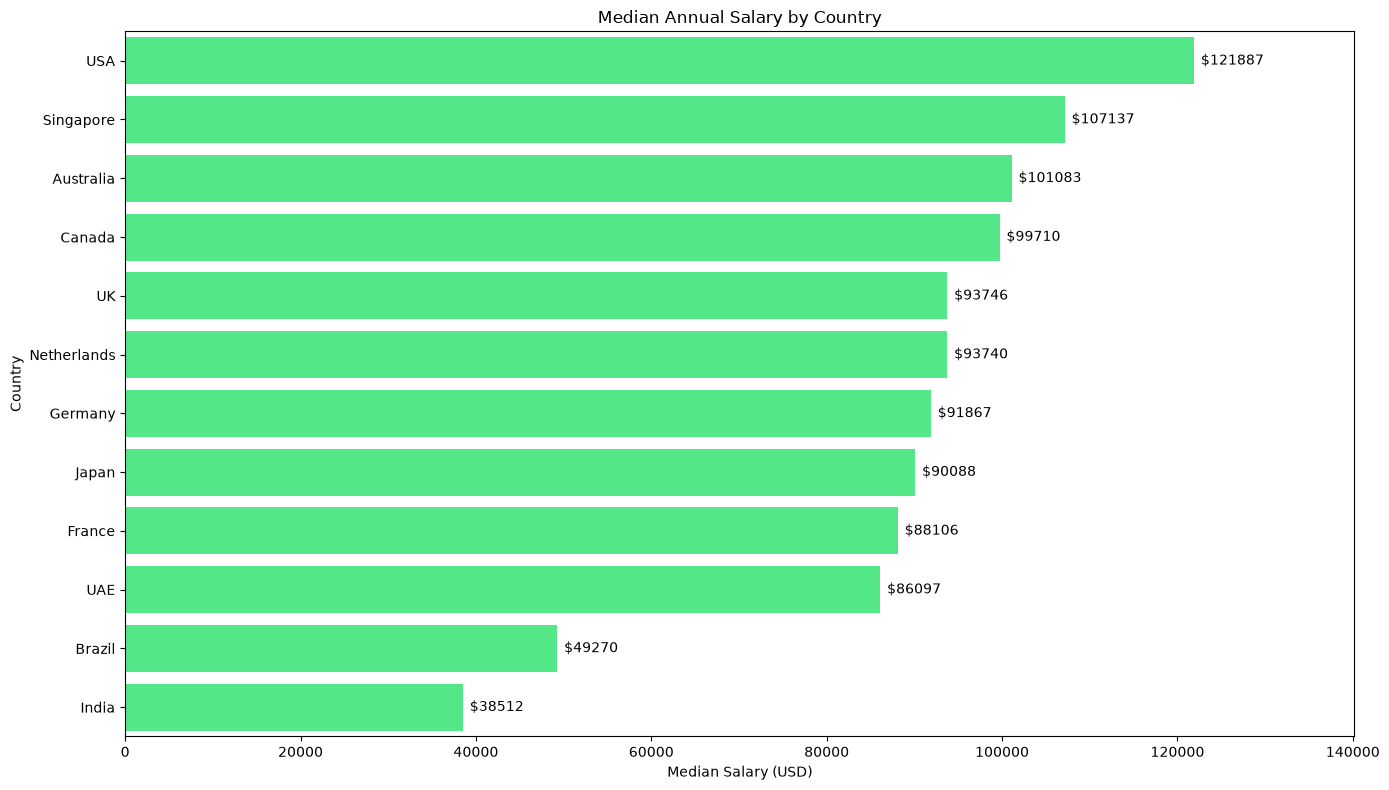

In [40]:
country_median = df.groupby("country")["salary_usd"].median().sort_values(ascending=False)

plt.figure(figsize=(14, 8))
ax = sns.barplot(x=country_median.values, y=country_median.index, color="#3BFF80")

ax.bar_label(ax.containers[0], fmt="$%.0f", padding=5)

plt.title("Median Annual Salary by Country")
plt.xlabel("Median Salary (USD)")
plt.ylabel("Country")

plt.xlim(0, country_median.max() * 1.15)
plt.tight_layout()
plt.show()

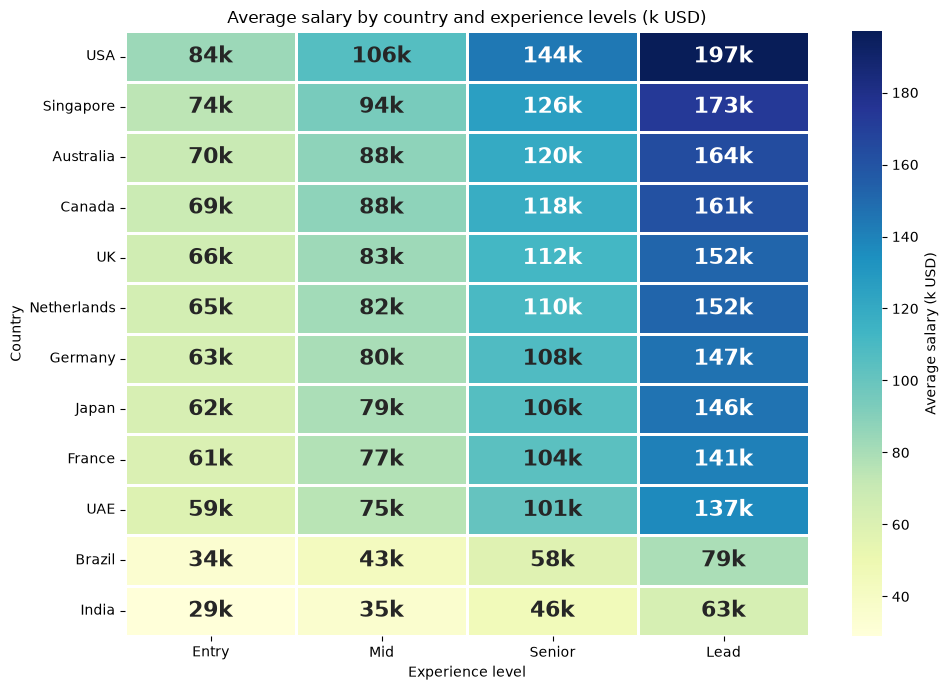

In [62]:
crosstab_df_cou_explvl = pd.crosstab(
    index=df['country'],
    columns=df['experience_level'],
    values=df['salary_usd'],
    aggfunc='mean'
)

crosstab_df_cou_explvl = crosstab_df_cou_explvl[['Entry', 'Mid', 'Senior', 'Lead']]
crosstab_df_cou_explvl = crosstab_df_cou_explvl.loc[
    crosstab_df_cou_explvl.mean(axis=1).sort_values(ascending=False).index
]

crosstab_df_cou_explvl = (crosstab_df_cou_explvl / 1000).round(0).astype(int)

signs = crosstab_df_cou_explvl.astype(str) + 'k'

plt.figure(figsize=(10, 7))
sns.heatmap(
    crosstab_df_cou_explvl,
    annot=signs,
    fmt='',
    annot_kws={'size': 16, 'weight': 'bold'},
    cmap='YlGnBu',
    linewidths=0.8,
    linecolor='white',
    cbar_kws={'label': 'Average salary (k USD)'}
)

plt.title('Average salary by country and experience levels (k USD)')
plt.xlabel('Experience level')
plt.ylabel('Country')
plt.tight_layout()
plt.show()